# Stage 5a – Counterfactual Explanations: *What could keep this customer?*

For contacted customers, finds the smallest realistic change that brings the model's churn probability below the customer's segment threshold (DiCE; Mothilal et al., 2020), and prices it.

**Design:**
1. Model and rule from Stage 4: LightGBM with segment thresholds. 100 contacted test customers per segment (fixed seed), or all if fewer.
2. Allowed changes: **Contract** (upgrade only); **OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport** (add only, internet customers); **MonthlyCharges** (−20% at most); **PaymentMethod** (to automatic only). Everything else is fixed.
3. DiCE random method, 3 counterfactuals per customer; each is re-scored and checked; more than 3 changes → dropped.
4. 12-month cost: discount = 12 × reduction; free add-on = 12 × estimated price; contract upgrade and automatic payment = 0. **Net value** = drop in probability × customer value − cost.
5. Sensitivity: 30% discount cap; contract upgrade costing the incentive *d*; plan B (contract fixed).

Counterfactuals describe the model, not cause and effect.

## Step 1 – Setup and data

In [1]:
# Cell 1 - Setup
import sys, math, time, warnings, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LinearRegression

ROOT = Path.cwd()
if ROOT.name in ("src", "notebooks"):
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

import config as C
from src import features as F
from src import modelling as M
import os
os.environ["TQDM_DISABLE"] = "1"               # hide DiCE's progress bars
import dice_ml
from raiutils.exceptions import UserConfigValidationException

warnings.filterwarnings("ignore")                    # DiCE prints many pandas warnings
logging.getLogger("dice_ml").setLevel(logging.ERROR)

train = pd.read_csv(C.PROCESSED_DIR / "train_segmented.csv")
test = pd.read_csv(C.PROCESSED_DIR / "test_segmented.csv")
X_train, y_train = F.get_X_y(train.drop(columns=["segment", "segment_k4"]))
X_test, y_test = F.get_X_y(test.drop(columns=["segment", "segment_k4"]))
SEGMENTS = ["Low-value", "New high-value", "Established high-value"]

stage4 = joblib.load(C.MODELS_DIR / "stage4_thresholds.joblib")
PRIMARY = stage4["primary_model"]
TH = stage4["thresholds"][PRIMARY]["P2"]             # segment thresholds of the primary model
D = stage4["incentive_d"]
assert PRIMARY == "LightGBM" and stage4["calibration"][PRIMARY] == "raw"
print("Primary model:", PRIMARY, "| segment thresholds:", TH, f"| incentive d = {D:.2f}")

SEG_COLOURS = {"Low-value": "#2a78d6", "New high-value": "#1baf7a", "Established high-value": "#4a3aa7"}
GREY = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(C.FIGURES_DIR / f"{name}.png"); print("Saved figure:", name)
def save_table(df, name):
    df.to_csv(C.TABLES_DIR / f"{name}.csv"); print("Saved table:", name)

Primary model: LightGBM | segment thresholds: {'Low-value': 0.23, 'New high-value': 0.17, 'Established high-value': 0.16} | incentive d = 39.00


## Step 2 – Rebuild the primary model
Refits LightGBM with the Stage 3 settings and checks it gives exactly the same test predictions.

In [2]:
# Cell 2 - Refit LightGBM and check it reproduces Stage 3
tuning = joblib.load(C.MODELS_DIR / "stage3_tuning.joblib")
params = (tuning.query("model == @PRIMARY and condition == 'none'")
          .sort_values("cv_auc", ascending=False).iloc[0]["params"])
clv_train = M.customer_value(train)
encoder, lgbm = M.fit_one(PRIMARY, params, "none", X_train, y_train.to_numpy(),
                          clv_train, D, F.make_encoder)

class ChurnModel:
    # DiCE gives us a table of customers; we encode it and return LightGBM probabilities
    def __init__(self, encoder, model, columns):
        self.encoder, self.model, self.columns = encoder, model, columns
    def predict_proba(self, X):
        return self.model.predict_proba(self.encoder.transform(X[self.columns]))
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)
    def p(self, X):
        return self.predict_proba(X)[:, 1]

model = ChurnModel(encoder, lgbm, list(X_train.columns))
p_test = model.p(X_test)
stage3 = pd.read_csv(C.PROCESSED_DIR / "stage3_test_predictions.csv")[f"{PRIMARY}|none|raw"].to_numpy()
print("Largest difference to the Stage 3 predictions:", float(np.abs(p_test - stage3).max()))
assert np.allclose(p_test, stage3, atol=1e-9)
print("Settings:", params)

Largest difference to the Stage 3 predictions: 9.71445146547012e-17
Settings: {'learning_rate': 0.010479569306192631, 'min_child_samples': 18, 'n_estimators': 443, 'num_leaves': 8}


## Step 3 – Which customers do we explain?
Contacted test customers (probability ≥ segment threshold); 100 per segment with a fixed seed, or all if fewer.

In [3]:
# Cell 3 - Contacted test customers and the sample
seg_test = test["segment"].to_numpy()
t_test = np.array([TH[s] for s in seg_test])
contacted = np.where(p_test >= t_test)[0]

rng = np.random.default_rng(C.RANDOM_STATE)
sample = []
for s in SEGMENTS:
    idx = contacted[seg_test[contacted] == s]
    sample.extend(sorted(rng.choice(idx, size=min(100, len(idx)), replace=False)))
sample = np.array(sample)

overview = pd.DataFrame({
    "test customers": pd.Series(seg_test).value_counts(),
    "contacted (P2)": pd.Series(seg_test[contacted]).value_counts(),
    "explained": pd.Series(seg_test[sample]).value_counts(),
}).loc[SEGMENTS]
overview["threshold"] = [TH[s] for s in SEGMENTS]
overview["mean churn probability (explained)"] = [p_test[sample][seg_test[sample] == s].mean().round(3) for s in SEGMENTS]
save_table(overview, "36_counterfactual_sample")
overview

Saved table: 36_counterfactual_sample


,test customers,contacted (P2),explained,threshold,mean churn probability (explained)
Low-value,446,95,95,0.23,0.394
New high-value,523,465,100,0.17,0.542
Established high-value,438,167,100,0.16,0.335


## Step 4 – Estimated monthly price of each add-on
Linear regression of MonthlyCharges on the service indicators (training customers only).

In [4]:
# Cell 4 - Estimated monthly price of each service
SERVICE_COLS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
S = pd.DataFrame({c: (X_train[c] == "Yes").astype(int) for c in SERVICE_COLS})
S["DSL"] = (X_train["InternetService"] == "DSL").astype(int)
S["Fiber optic"] = (X_train["InternetService"] == "Fiber optic").astype(int)
price_model = LinearRegression().fit(S, X_train["MonthlyCharges"])
prices = pd.Series(price_model.coef_, index=S.columns).round(2)
r2 = price_model.score(S, X_train["MonthlyCharges"])

ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
ADDON_PRICE = prices[ADDONS].to_dict()
price_table = prices.to_frame("estimated monthly price")
price_table.loc["(intercept)"] = round(price_model.intercept_, 2)
price_table["used as a retention action"] = [c in ADDONS for c in price_table.index]
save_table(price_table, "37_estimated_service_prices")
print(f"R² = {r2:.4f}")
price_table

Saved table: 37_estimated_service_prices
R² = 0.9988


,estimated monthly price,used as a retention action
PhoneService,20.06,False
MultipleLines,5.00,False
OnlineSecurity,5.02,True
OnlineBackup,4.96,True
DeviceProtection,5.04,True
TechSupport,5.06,True
StreamingTV,9.96,False
StreamingMovies,9.96,False
DSL,25.06,False
Fiber optic,50.01,False


## Step 5 – The rules: what may change, and how

| Feature | Allowed change | 12-month cost |
|---|---|---|
| Contract | month-to-month → one or two years; one year → two years | 0 (sensitivity: *d*) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | No → Yes (internet customers only) | 12 × estimated price |
| MonthlyCharges | down by at most 20% (sensitivity: 30%) | 12 × reduction |
| PaymentMethod | electronic / mailed check → automatic | 0 |
| everything else | fixed | – |

In [5]:
# Cell 5 - Actionability rules and costs
CONTRACTS = ["Month-to-month", "One year", "Two year"]
AUTO_PAY = ["Bank transfer (automatic)", "Credit card (automatic)"]
ACTIONABLE = ["Contract", "MonthlyCharges", "PaymentMethod"] + ADDONS

def allowed_changes(customer, cap=0.20, allow_contract=True):
    # features DiCE may vary for this customer, and the values each may take
    mc = customer["MonthlyCharges"]
    vary = ["MonthlyCharges"]
    ranges = {"MonthlyCharges": [math.ceil((1 - cap) * mc * 100) / 100, round(mc - 0.01, 2)]}
    k = CONTRACTS.index(customer["Contract"])
    if allow_contract and k < 2:
        vary.append("Contract"); ranges["Contract"] = CONTRACTS[k:]
    if customer["InternetService"] != "No":
        for a in ADDONS:
            if customer[a] == "No":
                vary.append(a); ranges[a] = ["No", "Yes"]
    if customer["PaymentMethod"] not in AUTO_PAY:
        vary.append("PaymentMethod"); ranges["PaymentMethod"] = [customer["PaymentMethod"]] + AUTO_PAY
    return vary, ranges

def changes(cf, customer):
    # list of features where the counterfactual differs from the customer
    out = []
    for c in X_train.columns:
        if c == "MonthlyCharges":
            if abs(cf[c] - customer[c]) > 0.005:
                out.append(c)
        elif cf[c] != customer[c]:
            out.append(c)
    return out

def follows_rules(cf, customer, cap=0.20):
    # the post-hoc check: every change must be allowed and in the allowed direction
    for c in changes(cf, customer):
        if c == "Contract":
            ok = CONTRACTS.index(cf[c]) > CONTRACTS.index(customer[c])
        elif c in ADDONS:
            ok = customer["InternetService"] != "No" and customer[c] == "No" and cf[c] == "Yes"
        elif c == "MonthlyCharges":
            ok = (1 - cap) * customer[c] - 0.01 <= cf[c] < customer[c]
        elif c == "PaymentMethod":
            ok = customer[c] not in AUTO_PAY and cf[c] in AUTO_PAY
        else:
            ok = False                                   # an immutable feature changed
        if not ok:
            return False
    return True

def cost_12m(cf, customer, contract_cost=0.0):
    cost = 12 * max(customer["MonthlyCharges"] - cf["MonthlyCharges"], 0)
    cost += sum(12 * ADDON_PRICE[a] for a in ADDONS if cf[a] != customer[a])
    if cf["Contract"] != customer["Contract"]:
        cost += contract_cost
    return cost

## Step 6 – Generate counterfactuals with DiCE
3 counterfactuals per customer, target = segment threshold. Clean-up: undo unnecessary changes (most expensive first) and shrink discounts to the smallest that still works; then re-score and check the rules.

In [6]:
# Cell 6 - DiCE set-up and the clean-up step
dice_data = dice_ml.Data(dataframe=pd.concat([X_train, y_train], axis=1),
                         continuous_features=["tenure", "MonthlyCharges"], outcome_name=C.TARGET)
dice = dice_ml.Dice(dice_data, dice_ml.Model(model=model, backend="sklearn"), method="random")
MAX_CHANGES = 3

def simplify(cf, customer, t):
    cf = cf.copy()
    # (1) undo unnecessary changes, most expensive first
    order = sorted(changes(cf, customer), key=lambda c: -cost_12m(
        pd.Series({**customer.to_dict(), c: cf[c]}), customer))
    for c in order:
        trial = cf.copy(); trial[c] = customer[c]
        if model.p(trial.to_frame().T.astype(X_train.dtypes.to_dict()))[0] < t:
            cf = trial
    # (2) smallest discount that still works
    if abs(cf["MonthlyCharges"] - customer["MonthlyCharges"]) > 0.005:
        needed = customer["MonthlyCharges"] - cf["MonthlyCharges"]
        for step in np.arange(0.01, needed / customer["MonthlyCharges"] + 1e-9, 0.01):
            trial = cf.copy(); trial["MonthlyCharges"] = round(customer["MonthlyCharges"] * (1 - step), 2)
            if model.p(trial.to_frame().T.astype(X_train.dtypes.to_dict()))[0] < t:
                cf = trial
                break
    return cf

def explain(i, cap=0.20, n_cf=3, allow_contract=True):
    customer = X_test.iloc[i]
    t = TH[seg_test[i]]
    vary, ranges = allowed_changes(customer, cap, allow_contract)
    try:
        res = dice.generate_counterfactuals(X_test.iloc[[i]], total_CFs=n_cf, desired_class=0,
                                            features_to_vary=vary, permitted_range=ranges,
                                            stopping_threshold=t - 1e-9, random_seed=C.RANDOM_STATE,
                                            posthoc_sparsity_param=None,   # we use our own clean-up below
                                            verbose=False)
    except UserConfigValidationException:          # DiCE raises an error when it finds nothing
        return customer, t, None
    raw = res.cf_examples_list[0].final_cfs_df
    if raw is None:
        return customer, t, None
    raw = raw[X_train.columns].astype(X_train.dtypes.to_dict()).reset_index(drop=True)
    return customer, t, raw

In [7]:
# Cell 7 - Run DiCE for every sampled customer and score every counterfactual
def run_all(cap=0.20, contract_cost=0.0, label="main", allow_contract=True):
    rows, t0 = [], time.time()
    for i in sample:
        customer, t, raw = explain(i, cap, allow_contract=allow_contract)
        clv = 12 * customer["MonthlyCharges"]
        base = dict(test_index=i, customerID=test.loc[i, C.ID_COL], segment=seg_test[i],
                    threshold=t, p_before=p_test[i], clv=clv, churn_actual=int(y_test.iloc[i]))
        if raw is None:
            rows.append({**base, "cf_id": -1})
            continue
        for j, cf_raw in raw.iterrows():
            p_raw = model.p(raw.iloc[[j]])[0]
            cf = simplify(cf_raw, customer, t)
            p_new = model.p(cf.to_frame().T.astype(X_train.dtypes.to_dict()))[0]
            ch = changes(cf, customer)
            cost = cost_12m(cf, customer, contract_cost)
            rows.append({**base, "cf_id": j,
                         "dice_valid": p_raw < t, "dice_n_changes": len(changes(cf_raw, customer)),
                         "dice_rules_ok": follows_rules(cf_raw, customer, cap),
                         "p_after": p_new, "valid": p_new < t, "rules_ok": follows_rules(cf, customer, cap),
                         "n_changes": len(ch), "changes": " + ".join(ch),
                         "discount_pct": 100 * (1 - cf["MonthlyCharges"] / customer["MonthlyCharges"]),
                         **{f"new_{c}": cf[c] for c in ACTIONABLE},
                         "cost_12m": cost, "delta_p": p_test[i] - p_new,
                         "net_value": (p_test[i] - p_new) * clv - cost})
    out = pd.DataFrame(rows)
    print(f"{label}: {len(sample)} customers, {int((out.cf_id >= 0).sum())} counterfactuals, "
          f"{time.time() - t0:.0f} s")
    return out

cfs = run_all()
cfs["usable"] = (cfs["cf_id"] >= 0) & cfs["valid"].fillna(False).astype(bool) \
                & cfs["rules_ok"].fillna(False).astype(bool) & (cfs["n_changes"] <= MAX_CHANGES)
cfs.to_csv(C.PROCESSED_DIR / "stage5_counterfactuals.csv", index=False)
print("Saved data/processed/stage5_counterfactuals.csv")
cfs.loc[cfs.cf_id >= 0, ["customerID", "segment", "p_before", "p_after", "changes",
                         "discount_pct", "cost_12m", "net_value"]].head(9).round(3)

main: 295 customers, 885 counterfactuals, 271 s
Saved data/processed/stage5_counterfactuals.csv


,customerID,segment,p_before,p_after,changes,discount_pct,cost_12m,net_value
0,2465-BLLEU,Low-value,0.385,0.092,Contract,0.00,0.00,69.318
1,2465-BLLEU,Low-value,0.385,0.092,Contract,0.00,0.00,69.318
2,2465-BLLEU,Low-value,0.385,0.039,Contract,0.00,0.00,81.982
3,5049-GLYVG,Low-value,0.325,0.219,MonthlyCharges,6.99,17.28,8.922
4,5049-GLYVG,Low-value,0.325,0.219,MonthlyCharges,6.99,17.28,8.922
5,5049-GLYVG,Low-value,0.325,0.219,MonthlyCharges,6.99,17.28,8.922
6,6137-MFAJN,Low-value,0.279,0.049,Contract,0.00,0.00,123.994
7,6137-MFAJN,Low-value,0.279,0.182,PaymentMethod,0.00,0.00,52.473
8,6137-MFAJN,Low-value,0.279,0.183,PaymentMethod,0.00,0.00,51.963


## Step 7 – Quality metrics
Validity, feasibility, sparsity (number of changes), proximity (discount size), diversity, and share with no actionable option.

In [8]:
# Cell 8 - Quality metrics per segment
def diversity(g):
    sets = [set(s.split(" + ")) if s else set() for s in g.drop_duplicates("changes")["changes"]]
    if len(g) < 2:
        return 0.0
    pairs = [(a, b) for k, a in enumerate(sets) for b in sets[k + 1:]]
    n_pairs = len(g) * (len(g) - 1) / 2                  # identical counterfactuals count as distance 0
    return sum(len(a ^ b) for a, b in pairs) / n_pairs

def quality(df):
    found = df[df.cf_id >= 0]
    usable = df[df.usable]
    per_customer = df.groupby("test_index")["usable"].any()
    div = usable.groupby("test_index").apply(diversity)
    return pd.Series({
        "customers": df.test_index.nunique(),
        "counterfactuals from DiCE": len(found),
        "validity (DiCE output, %)": 100 * found.dice_valid.mean(),
        "feasibility (DiCE output, %)": 100 * found.dice_rules_ok.mean(),
        "changes per CF (DiCE output)": found.dice_n_changes.mean(),
        "validity after clean-up (%)": 100 * found.valid.mean(),
        "feasibility after clean-up (%)": 100 * found.rules_ok.mean(),
        "changes per CF (after clean-up)": found.n_changes.mean(),
        "mean discount among CFs with a discount (%)": usable.loc[usable.discount_pct > 0.5, "discount_pct"].mean(),
        "diversity (features)": div.mean(),
        "distinct usable CFs per customer": usable.drop_duplicates(["test_index", "changes"]).groupby("test_index").size().mean(),
        "no actionable option (%)": 100 * (1 - per_customer.mean()),
    })

q_table = pd.DataFrame({s: quality(cfs[cfs.segment == s]) for s in SEGMENTS})
q_table["All"] = quality(cfs)
save_table(q_table.round(2), "38_counterfactual_quality")
q_table.round(2)

Saved table: 38_counterfactual_quality


,Low-value,New high-value,Established high-value,All
customers,95.00,100.00,100.00,295.00
counterfactuals from DiCE,285.00,300.00,300.00,885.00
"validity (DiCE output, %)",100.00,100.00,100.00,100.00
"feasibility (DiCE output, %)",100.00,100.00,100.00,100.00
changes per CF (DiCE output),1.93,1.96,1.88,1.92
validity after clean-up (%),100.00,100.00,100.00,100.00
feasibility after clean-up (%),100.00,100.00,100.00,100.00
changes per CF (after clean-up),1.04,1.05,1.12,1.07
mean discount among CFs with a discount (%),4.13,7.70,10.44,8.43
diversity (features),0.29,0.08,0.28,0.22


## Step 8 – The recommended action for each customer
The counterfactual with the highest net value; customers whose best option has negative net value are flagged.

In [9]:
# Cell 9 - Best counterfactual per customer
def recommend(df):
    best = (df[df.usable].sort_values("net_value", ascending=False)
            .groupby("test_index").head(1).set_index("test_index"))
    return best

best = recommend(cfs)
best["action type"] = best["changes"].str.replace("MonthlyCharges", "Discount")

def economics(best, df):
    rows = {}
    for s in SEGMENTS + ["All"]:
        b = best if s == "All" else best[best.segment == s]
        n = df.test_index.nunique() if s == "All" else df[df.segment == s].test_index.nunique()
        rows[s] = {
            "customers explained": n,
            "with a recommended action": len(b),
            "mean churn probability before": b.p_before.mean(),
            "mean churn probability after": b.p_after.mean(),
            "mean drop in probability": b.delta_p.mean(),
            "mean customer value (12 months)": b.clv.mean(),
            "mean 12-month cost": b.cost_12m.mean(),
            "mean net value": b.net_value.mean(),
            "share with negative net value (%)": 100 * (b.net_value < 0).mean(),
            "median discount when used (%)": b.loc[b.discount_pct > 0.5, "discount_pct"].median(),
            "uses a discount (%)": 100 * (b.discount_pct > 0.5).mean(),
        }
    return pd.DataFrame(rows)

econ = economics(best, cfs)
save_table(econ.round(3), "39_recommended_action_economics")
econ.round(3)

Saved table: 39_recommended_action_economics


,Low-value,New high-value,Established high-value,All
customers explained,95.000,100.000,100.000,295.000
with a recommended action,95.000,100.000,100.000,295.000
mean churn probability before,0.394,0.542,0.335,0.424
mean churn probability after,0.077,0.082,0.093,0.084
mean drop in probability,0.317,0.460,0.242,0.340
mean customer value (12 months),360.347,893.940,1176.306,817.822
mean 12-month cost,0.435,0.102,11.567,4.095
mean net value,112.475,421.916,271.139,271.155
share with negative net value (%),0.000,0.000,8.000,2.712
median discount when used (%),4.506,1.001,7.003,6.994


Saved table: 40_action_frequency_by_segment
Saved figure: 18_counterfactual_actions_by_segment


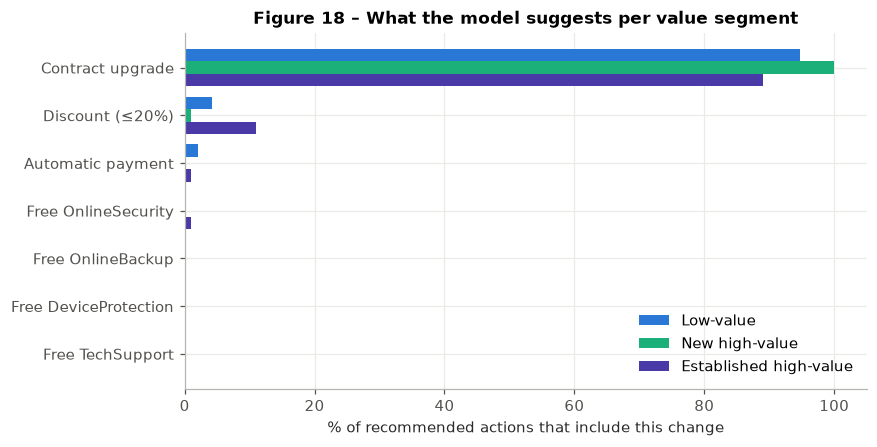

,Low-value,New high-value,Established high-value
Contract upgrade,94.7,100.0,89.0
Discount (≤20%),4.2,1.0,11.0
Automatic payment,2.1,0.0,1.0
Free OnlineSecurity,0.0,0.0,1.0
Free OnlineBackup,0.0,0.0,0.0
Free DeviceProtection,0.0,0.0,0.0
Free TechSupport,0.0,0.0,0.0


In [10]:
# Cell 10 - How often is each action part of the recommendation?
ACTION_NAMES = {"Contract": "Contract upgrade", "MonthlyCharges": "Discount (≤20%)",
                "PaymentMethod": "Automatic payment", **{a: f"Free {a}" for a in ADDONS}}
freq = pd.DataFrame({s: [100 * best.loc[best.segment == s, "changes"].str.contains(a).mean()
                         for a in ACTION_NAMES] for s in SEGMENTS}, index=list(ACTION_NAMES.values()))
save_table(freq.round(1), "40_action_frequency_by_segment")

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(freq))
h = 0.26
for k, s in enumerate(SEGMENTS):
    ax.barh(y + (k - 1) * h, freq[s], height=h, color=SEG_COLOURS[s], label=s)
ax.set_yticks(y, freq.index); ax.invert_yaxis()
ax.set_xlabel("% of recommended actions that include this change")
ax.set_title("Figure 18 – What the model suggests per value segment")
ax.legend(loc="lower right")
save(fig, "18_counterfactual_actions_by_segment")
plt.show()
freq.round(1)

Saved figure: 19_counterfactual_economics


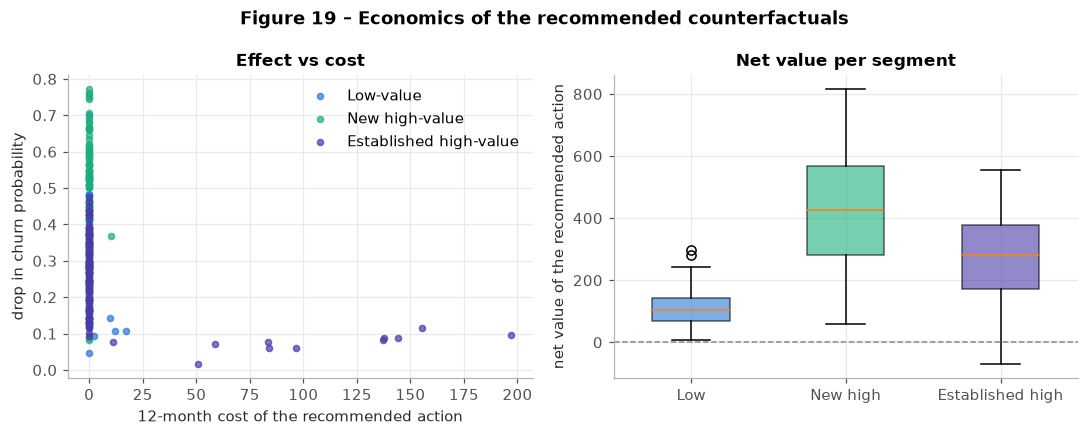

In [11]:
# Cell 11 - Drop in churn probability against cost
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for s in SEGMENTS:
    b = best[best.segment == s]
    axes[0].scatter(b.cost_12m, b.delta_p, s=16, alpha=0.7, color=SEG_COLOURS[s], label=s)
axes[0].set_xlabel("12-month cost of the recommended action"); axes[0].set_ylabel("drop in churn probability")
axes[0].set_title("Effect vs cost"); axes[0].legend()
data = [best.loc[best.segment == s, "net_value"] for s in SEGMENTS]
bp = axes[1].boxplot(data, patch_artist=True, widths=0.5)
for patch, s in zip(bp["boxes"], SEGMENTS):
    patch.set_facecolor(SEG_COLOURS[s]); patch.set_alpha(0.6)
axes[1].set_xticks([1, 2, 3], ["Low", "New high", "Established high"])
axes[1].axhline(0, color=GREY, lw=1, ls="--")
axes[1].set_ylabel("net value of the recommended action"); axes[1].set_title("Net value per segment")
fig.suptitle("Figure 19 – Economics of the recommended counterfactuals", fontweight="bold")
fig.tight_layout()
save(fig, "19_counterfactual_economics")
plt.show()

## Step 9 – Segment playbook
Most frequent recommended actions per segment, with their effect, cost and net value.

In [12]:
# Cell 12 - Segment playbook (top 3 action combinations per segment)
rows = []
for s in SEGMENTS:
    b = best[best.segment == s]
    top = b["action type"].value_counts().head(3)
    for action, n in top.items():
        g = b[b["action type"] == action]
        rows.append({"segment": s, "recommended action": action, "customers": n,
                     "share of segment (%)": 100 * n / len(b),
                     "mean drop in probability": g.delta_p.mean(), "mean cost": g.cost_12m.mean(),
                     "mean net value": g.net_value.mean(),
                     "median discount (%)": g.loc[g.discount_pct > 0.5, "discount_pct"].median()})
playbook = pd.DataFrame(rows).set_index(["segment", "recommended action"])
save_table(playbook.round(3), "41_segment_playbook")
playbook.round(3)

Saved table: 41_segment_playbook


customers  \
segment                recommended action                    
Low-value              Contract                         90   
                       Discount                          3   
                       PaymentMethod                     1   
New high-value         Contract                         99   
                       Contract + Discount               1   
Established high-value Contract                         89   
                       Discount                          9   
                       PaymentMethod + Discount          1   

                                                 share of segment (%)  \
segment                recommended action                               
Low-value              Contract                                94.737   
                       Discount                                 3.158   
                       PaymentMethod                            1.053   
New high-value         Contract                                99.000   
                       Contract + Discount                      1.000   
Established high-value Contract                                89.000   
                       Discount                                 9.000   
                       PaymentMethod + Discount                 1.000   

                                                 mean drop in probability  \
segment                recommended action                                   
Low-value              Contract                                     0.329   
                       Discount                                     0.102   
                       PaymentMethod                                0.047   
New high-value         Contract                                     0.461   
                       Contract + Discount                          0.368   
Established high-value Contract                                     0.263   
                       Discount                                     0.074   
                       PaymentMethod + Discount                     0.078   

                                                 mean cost  mean net value  \
segment                recommended action                                    
Low-value              Contract                       0.00         117.638   
                       Discount                      10.56          13.897   
                       PaymentMethod                  0.00          31.068   
New high-value         Contract                       0.00         422.494   
                       Contract + Discount           10.20         364.770   
Established high-value Contract                       0.00         306.146   
                       Discount                     111.24         -19.015   
                       PaymentMethod + Discount      11.28          76.909   

                                                 median discount (%)  
segment                recommended action                             
Low-value              Contract                                  NaN  
                       Discount                                5.012  
                       PaymentMethod                             NaN  
New high-value         Contract                                  NaN  
                       Contract + Discount                     1.001  
Established high-value Contract                                  NaN  
                       Discount                                8.004  
                       PaymentMethod + Discount                0.998

In [13]:
# Cell 13 - Three example customers (one per segment)
examples = []
for s in SEGMENTS:
    b = best[best.segment == s].sort_values("net_value", ascending=False)
    i = b.index[len(b) // 2]                              # a typical (median net value) customer
    r = best.loc[i]; cust = X_test.iloc[i]
    examples.append({"segment": s, "tenure": cust["tenure"], "contract": cust["Contract"],
                     "payment": cust["PaymentMethod"], "monthly charge": cust["MonthlyCharges"],
                     "churn prob. before": round(r.p_before, 3), "threshold": r.threshold,
                     "suggested change": r["action type"],
                     "new monthly charge": round(r.new_MonthlyCharges, 2),
                     "churn prob. after": round(r.p_after, 3), "12-month cost": round(r.cost_12m, 2),
                     "net value": round(r.net_value, 2)})
pd.DataFrame(examples).set_index("segment").T

segment,Low-value,New high-value,Established high-value
tenure,12,2,35
contract,Month-to-month,Month-to-month,Month-to-month
payment,Bank transfer (automatic),Bank transfer (automatic),Bank transfer (automatic)
monthly charge,45.0,70.0,100.5
churn prob. before,0.234,0.548,0.319
threshold,0.23,0.17,0.16
suggested change,Contract,Contract,Contract
new monthly charge,45.0,70.0,100.5
churn prob. after,0.04,0.041,0.086
12-month cost,0.0,0.0,0.0


## Step 10 – Sensitivity
1. Discount cap 30% instead of 20%.
2. Contract upgrade costs the incentive *d* (≈ 39).
3. Plan B: the contract is fixed, so DiCE must find other changes.

In [14]:
# Cell 14 - Sensitivity analyses
cfs30 = run_all(cap=0.30, label="cap 30%")
cfs30["usable"] = (cfs30["cf_id"] >= 0) & cfs30["valid"].fillna(False).astype(bool) \
                  & cfs30["rules_ok"].fillna(False).astype(bool) & (cfs30["n_changes"] <= MAX_CHANGES)

cfsd = cfs.copy()
paid = cfsd["changes"].fillna("").str.contains("Contract")
cfsd.loc[paid, "cost_12m"] += D
cfsd["net_value"] = cfsd["delta_p"] * cfsd["clv"] - cfsd["cost_12m"]

def summary(df, label):
    b = recommend(df)
    out = []
    for s in SEGMENTS + ["All"]:
        bb = b if s == "All" else b[b.segment == s]
        n = df.test_index.nunique() if s == "All" else df[df.segment == s].test_index.nunique()
        out.append({"scenario": label, "segment": s,
                    "no actionable option (%)": 100 * (1 - len(bb) / n),
                    "contract upgrade in recommendation (%)": 100 * bb.changes.str.contains("Contract").mean(),
                    "discount in recommendation (%)": 100 * (bb.discount_pct > 0.5).mean(),
                    "mean cost": bb.cost_12m.mean(), "mean net value": bb.net_value.mean(),
                    "negative net value (%)": 100 * (bb.net_value < 0).mean()})
    return out

cfsnc = run_all(label="contract fixed", allow_contract=False)
cfsnc["usable"] = (cfsnc["cf_id"] >= 0) & cfsnc["valid"].fillna(False).astype(bool) \
                  & cfsnc["rules_ok"].fillna(False).astype(bool) & (cfsnc["n_changes"] <= MAX_CHANGES)

sens = pd.DataFrame(summary(cfs, "main (cap 20%, contract free)") + summary(cfs30, "discount cap 30%")
                    + summary(cfsd, "contract upgrade costs d")
                    + summary(cfsnc, "plan B: contract fixed")).set_index(["scenario", "segment"])
save_table(sens.round(2), "42_counterfactual_sensitivity")
sens.round(2)

cap 30%: 295 customers, 885 counterfactuals, 284 s
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 01 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 01 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 01 sec
No Counterfactuals found for the given configuration, perhaps try with different parameters... ; total time taken: 00 min 00 sec
No Counterfactuals found for the given configu

no actionable option (%)  \
scenario                      segment                                            
main (cap 20%, contract free) Low-value                                   0.00   
                              New high-value                              0.00   
                              Established high-value                      0.00   
                              All                                         0.00   
discount cap 30%              Low-value                                   0.00   
                              New high-value                              0.00   
                              Established high-value                      0.00   
                              All                                         0.00   
contract upgrade costs d      Low-value                                   0.00   
                              New high-value                              0.00   
                              Established high-value                      0.00   
                              All                                         0.00   
plan B: contract fixed        Low-value                                  44.21   
                              New high-value                             94.00   
                              Established high-value                     65.00   
                              All                                        68.14   

                                                      contract upgrade in recommendation (%)  \
scenario                      segment                                                          
main (cap 20%, contract free) Low-value                                                94.74   
                              New high-value                                          100.00   
                              Established high-value                                   89.00   
                              All                                                      94.58   
discount cap 30%              Low-value                                                82.11   
                              New high-value                                           99.00   
                              Established high-value                                   87.00   
                              All                                                      89.49   
contract upgrade costs d      Low-value                                                88.42   
                              New high-value                                          100.00   
                              Established high-value                                   89.00   
                              All                                                      92.54   
plan B: contract fixed        Low-value                                                 0.00   
                              New high-value                                            0.00   
                              Established high-value                                    0.00   
                              All                                                       0.00   

                                                      discount in recommendation (%)  \
scenario                      segment                                                  
main (cap 20%, contract free) Low-value                                         4.21   
                              New high-value                                    1.00   
                              Established high-value                           11.00   
                              All                                               5.42   
discount cap 30%              Low-value                                        11.58   
                              New high-value                                    2.00   
                              Established high-value                           16.00   
                              All                       

In [15]:
# Cell 15 - Plan B playbook: what to offer when the customer will not sign a longer contract
best_nc = recommend(cfsnc)
best_nc["action type"] = best_nc["changes"].str.replace("MonthlyCharges", "Discount")
rows = []
for s in SEGMENTS:
    b = best_nc[best_nc.segment == s]
    n_all = cfsnc[cfsnc.segment == s].test_index.nunique()
    rows.append({"segment": s, "recommended action": "(no actionable option)", "customers": n_all - len(b),
                 "share of segment (%)": 100 * (n_all - len(b)) / n_all})
    for action, n in b["action type"].value_counts().head(3).items():
        g = b[b["action type"] == action]
        rows.append({"segment": s, "recommended action": action, "customers": n,
                     "share of segment (%)": 100 * n / n_all,
                     "mean drop in probability": g.delta_p.mean(), "mean cost": g.cost_12m.mean(),
                     "mean net value": g.net_value.mean(),
                     "negative net value (%)": 100 * (g.net_value < 0).mean(),
                     "median discount (%)": g.loc[g.discount_pct > 0.5, "discount_pct"].median()})
playbook_b = pd.DataFrame(rows).set_index(["segment", "recommended action"])
save_table(playbook_b.round(3), "43_segment_playbook_plan_b")
playbook_b.round(3)

Saved table: 43_segment_playbook_plan_b


customers  \
segment                recommended action                       
Low-value              (no actionable option)              42   
                       Discount                            17   
                       PaymentMethod                       11   
                       TechSupport + PaymentMethod          6   
New high-value         (no actionable option)              94   
                       PaymentMethod                        2   
                       TechSupport + Discount               1   
                       OnlineBackup                         1   
Established high-value (no actionable option)              65   
                       Discount                            20   
                       PaymentMethod + Discount             7   
                       OnlineSecurity + Discount            4   

                                                    share of segment (%)  \
segment                recommended action                                  
Low-value              (no actionable option)                     44.211   
                       Discount                                   17.895   
                       PaymentMethod                              11.579   
                       TechSupport + PaymentMethod                 6.316   
New high-value         (no actionable option)                     94.000   
                       PaymentMethod                               2.000   
                       TechSupport + Discount                      1.000   
                       OnlineBackup                                1.000   
Established high-value (no actionable option)                     65.000   
                       Discount                                   20.000   
                       PaymentMethod + Discount                    7.000   
                       OnlineSecurity + Discount                   4.000   

                                                    mean drop in probability  \
segment                recommended action                                      
Low-value              (no actionable option)                            NaN   
                       Discount                                        0.104   
                       PaymentMethod                                   0.094   
                       TechSupport + PaymentMethod                     0.163   
New high-value         (no actionable option)                            NaN   
                       PaymentMethod                                   0.016   
                       TechSupport + Discount                          0.099   
                       OnlineBackup                                    0.013   
Established high-value (no actionable option)                            NaN   
                       Discount                                        0.082   
                       PaymentMethod + Discount                        0.106   
                       OnlineSecurity + Discount                       0.145   

                                                    mean cost  mean net value  \
segment                recommended action                                       
Low-value              (no actionable option)             NaN             NaN   
                       Discount                        10.045          14.803   
                       PaymentMethod                    0.000          44.970   
                       TechSupport + PaymentMethod     60.720          25.422   
New high-value         (no actionable option)             NaN             NaN   
                       PaymentMethod                    0.000          14.527   
                       TechSupport + Discount          95.160          18.428   
                       OnlineBackup                    59.520         -48.974   
Established high-value (no actionable option)             NaN             NaN   
                       Discount                       143.958   

## Findings
**1. Quality:** 295 customers explained; validity and feasibility 100%; about one change per counterfactual (1.07); low diversity (1.3 distinct options per customer).

**2. Main lever = contract upgrade:** part of the recommended action for **95%** of customers (low-value 95%, new high-value 100%, established high-value 89%). Mean churn probability 0.42 → 0.08; mean net value 271.

**3. Segments:** new high-value customers have the largest drop (−0.46). Discounts appear mainly for established high-value customers (11%), and often cost more than they save (8% negative net value).

**4. Plan B (contract fixed):** 68% of customers have no feasible option (new high-value 94%, established high-value 65%, low-value 44%). Only low-value customers have cheap options that pay off (automatic payment, about 3% discount).

**5. Sensitivity:** 30% cap → discounts 10% instead of 5%; contract costed at *d* → net value 271 → 234, contract still recommended for 93%.

**Limitation:** model-based, not causal – offers to test with an A/B campaign.

**Carried forward:** recommended actions and playbooks (Tables 41 and 43).